In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import f1_score, classification_report, confusion_matrix, make_scorer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42  # Zelfde voor alle teamleden (afspraak gezamenlijke start)

# Uitzetten warnings voor opmaak
# warnings.filterwarnings('ignore')


# Opdracht 1: Voorspel Herseninfarct (Stroke Prediction)
**Competitie:** Predicting stroke 2026-27 | Kaggle  
**Teamnaam:**   Groep 4 <br>
**Teamleden & Kaggle Usernames:**  
- Kaman - [Kaggle Username 1]  
- Alex - [Kaggle Username 2]  
- Pablo - [Kaggle Username 3]  

## 1. Inleiding
In dit project werken we als junior data scientists bij *MedPredict*. Het doel is om een machine learning model te ontwikkelen dat op basis van demografische, leefstijl- en medische gegevens kan voorspellen of een patiënt een verhoogd risico loopt op een herseninfarct (stroke). Dit model zal zorgprofessionals ondersteunen bij preventie en gerichte opvolging.

In [2]:
train_df = pd.read_csv("train.csv")
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

## 2. Data & Exploratieve Data Analyse (EDA)

### Uitleg van de kolommen
De dataset bevat al numerieke waarden en dummyvariabelen. De kolommen betekenen:
- **id**: unieke identificatie van de patiënt. Deze kolom wordt niet als voorspeller gebruikt.
- **age**: leeftijd van de patiënt in jaren.
- **hypertension**: indicator voor hoge bloeddruk; 0 = nee, 1 = ja.
- **heart_disease**: indicator voor hartziekte; 0 = nee, 1 = ja.
- **avg_glucose_level**: gemiddeld glucosegehalte in het bloed.
- **bmi**: Body Mass Index, een maat voor gewicht in verhouding tot lengte.
- **gender_Female**, **gender_Male**, **gender_Other**: dummyvariabelen voor het geregistreerde geslacht.
- **ever_married_No**, **ever_married_Yes**: dummyvariabelen voor de burgerlijke staat.
- **work_type_Govt_job**, **work_type_Never_worked**, **work_type_Private**, **work_type_Self-employed**, **work_type_children**: dummyvariabelen voor het soort werk.
- **Residence_type_Rural**, **Residence_type_Urban**: dummyvariabelen voor het type woonomgeving.
- **smoking_status_formerly smoked**, **smoking_status_never smoked**, **smoking_status_smokes**: dummyvariabelen voor rookstatus. Een eventuele niet-rokerstatus die niet als aparte kolom voorkomt, is de referentiecategorie.
- **stroke**: doelvariabele; 1 betekent dat de patiënt een herseninfarct heeft gehad en 0 dat niet. Deze kolom ontbreekt in `test.csv`.


In [3]:
class DataLoader:
    """Klasse voor het inladen en inspecteren van de data."""
    
    def __init__(self, train_path, test_path):
        self.train_path = train_path
        self.test_path = test_path
        
    def load_data(self):
        """Laadt de train en test datasets in."""
        # De CSV-bestanden bevatten een header-rij met kolomnamen,
        # dus we lezen ze in met de standaard header=0.
        self.train_df = pd.read_csv(self.train_path)
        self.test_df = pd.read_csv(self.test_path)
        
        # Converteer booleans (True/False) naar integers (1/0) voor Scikit-Learn
        bool_cols = self.train_df.select_dtypes(include=['bool']).columns
        for col in bool_cols:
            self.train_df[col] = self.train_df[col].astype(int)
            if col in self.test_df.columns:
                self.test_df[col] = self.test_df[col].astype(int)
                
        return self.train_df, self.test_df

# Inladen van de data
loader = DataLoader('train.csv', 'test.csv')
train_df, test_df = loader.load_data()

print("Train Data Shape:", train_df.shape)
print("Test Data Shape:", test_df.shape)
train_df.head()

Train Data Shape: (33550, 22)
Test Data Shape: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0
1,72295,75.0,1,0,215.17,48.0,1,0,0,0,...,0,0,1,0,1,0,0,1,0,0
2,26451,15.0,0,0,135.22,19.0,0,1,0,1,...,0,1,0,0,1,0,0,1,0,0
3,65210,47.0,0,0,64.89,28.2,0,1,0,0,...,0,0,1,0,0,1,0,1,0,0
4,69299,49.0,0,0,222.34,28.8,0,1,0,0,...,0,0,1,0,1,0,1,0,0,0


### 3.a. Minimale vereisten voor Machine Learning met Scikit-Learn
Scikit-Learn verwacht dat de invoervariabelen numeriek zijn en dat het gekozen algoritme met ontbrekende waarden kan omgaan. De dummyvariabelen zijn booleans en worden in de laadfunctie omgezet naar 0 en 1. In deze aangeleverde dataset zijn geen ontbrekende BMI-waarden aangetroffen. De imputatiestap blijft wel in de pipeline staan als robuuste bescherming wanneer een vergelijkbare dataset later wel ontbrekende waarden bevat.

De dataset bevat 33.550 patiënten. Daarvan hebben 517 patiënten `stroke = 1` en 33.033 patiënten `stroke = 0`; het positieve aandeel is ongeveer 1,54%. Daarmee is de target sterk imbalanced. De kolom `id` is een identificatienummer en wordt verwijderd, omdat deze geen inhoudelijke voorspeller is.

### 3.b. Datatypes en basisstatistieken


In [4]:
def show_basic_stats(df):
    """Toont datatypes en statistieken."""
    print("--- Data Types ---")
    print(df.dtypes.value_counts())
    print("\n--- Basisstatistieken ---")
    display(df.describe())
    
    # Check voor missing values
    missing = df.isnull().sum()
    if missing.sum() > 0:
        print("\n--- Missing Values ---")
        print(missing[missing > 0])
    else:
        print("\nGeen missing values gevonden in de basisinspectie.")

show_basic_stats(train_df)

--- Data Types ---
int64      19
float64     3
Name: count, dtype: int64

--- Basisstatistieken ---


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,...,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.597079,0.402742,0.000179,0.361371,...,0.004203,0.574635,0.152787,0.144501,0.499970,0.500030,0.168733,0.375618,0.148048,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.490492,0.490457,0.013372,0.480405,...,0.064693,0.494406,0.359787,0.351602,0.500007,0.500007,0.374522,0.484289,0.355153,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,1.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,1.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Geen missing values gevonden in de basisinspectie.


### 3.c. Relaties tussen variabelen (Visualisaties)
We onderzoeken de relatie tussen de onafhankelijke variabelen en de target (`stroke`).

C:\Users\kaman\AppData\Local\Temp\ipykernel_20072\1336553462.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stroke', data=df, ax=axes[0, 0], palette='Set2')
C:\Users\kaman\AppData\Local\Temp\ipykernel_20072\1336553462.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y='age', data=df, ax=axes[0, 1], palette='Set2')
C:\Users\kaman\AppData\Local\Temp\ipykernel_20072\1336553462.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[1, 0], palette='Set2')
C:\Users\kaman\A

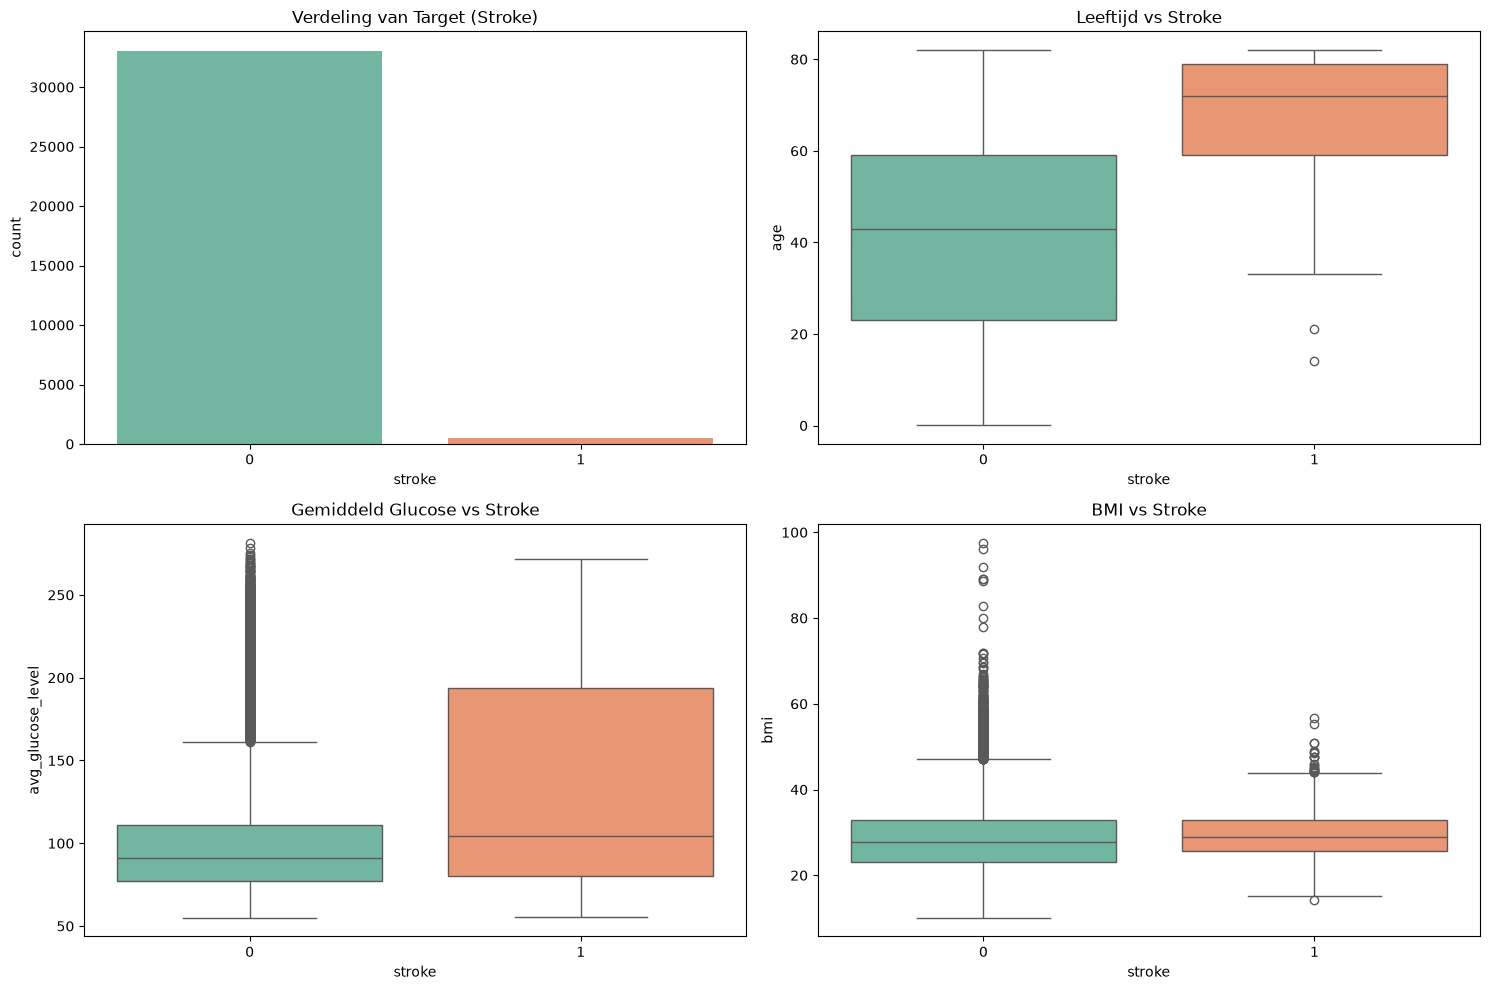

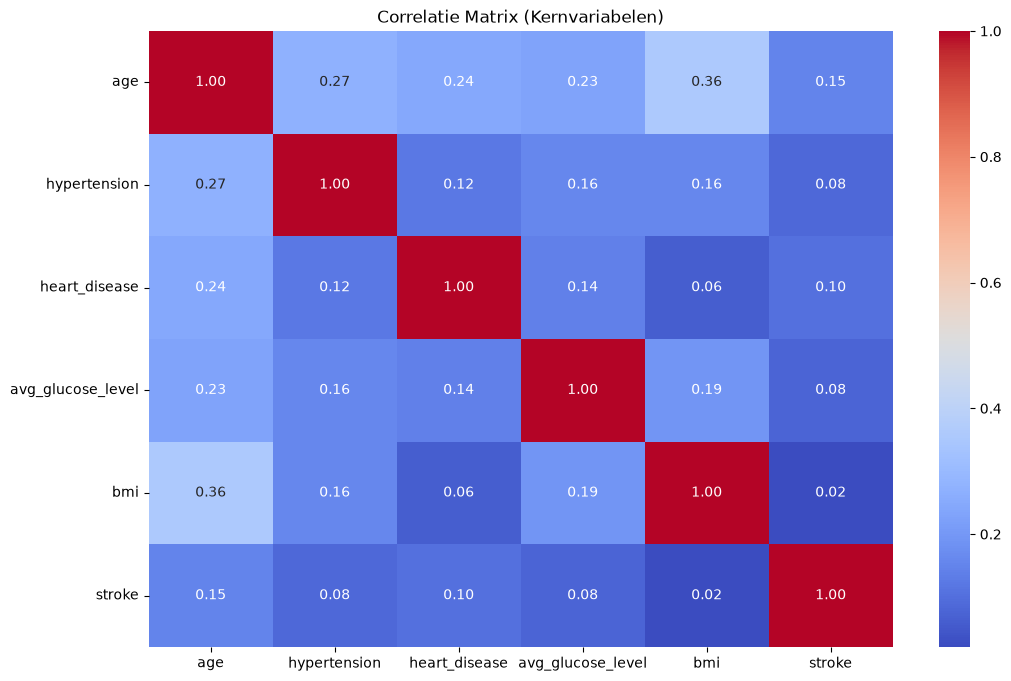

In [5]:
def plot_eda(df):
    """Genereert EDA visualisaties."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # 1. Verdeling van Stroke (Imbalanced check)
    sns.countplot(x='stroke', data=df, ax=axes[0, 0], palette='Set2')
    axes[0, 0].set_title('Verdeling van Target (Stroke)')
    
    # 2. Leeftijd vs Stroke
    sns.boxplot(x='stroke', y='age', data=df, ax=axes[0, 1], palette='Set2')
    axes[0, 1].set_title('Leeftijd vs Stroke')
    
    # 3. Glucose vs Stroke
    sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[1, 0], palette='Set2')
    axes[1, 0].set_title('Gemiddeld Glucose vs Stroke')
    
    # 4. BMI vs Stroke
    sns.boxplot(x='stroke', y='bmi', data=df, ax=axes[1, 1], palette='Set2')
    axes[1, 1].set_title('BMI vs Stroke')
    
    plt.tight_layout()
    plt.show()

plot_eda(train_df)

# Correlatie matrix
plt.figure(figsize=(12, 8))
# We selecteren alleen de numerieke kernvariabelen voor de correlatie heatmap
num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
sns.heatmap(train_df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlatie Matrix (Kernvariabelen)')
plt.show()

### 3.d. Belangrijkste bevindingen van de EDA
1. **Zeer Imbalanced Dataset**: Het overgrote deel van de patiënten heeft geen stroke (0). Slechts een klein percentage heeft wel een stroke (1).
2. **Leeftijd**: Patiënten met een stroke zijn gemiddeld significant ouder.
3. **Glucose & BMI**: Er is een zichtbare correlatie; hogere glucosewaarden en extremere BMI-waarden lijken vaker voor te komen bij de stroke-groep.
4. **Hypertension & Heart Disease**: Deze binaire variabelen tonen een sterke positieve correlatie met de target.

### 4. Data Opschonen
We verwijderen de `id` kolom. Omdat Scikit-Learn niet goed omgaat met NaN's in sommige algoritmen, voegen we een imputatie-stap toe in onze modeling pipeline.

In [6]:
def clean_data(train_df, test_df):
    """Verwijdert irrelevante kolommen."""
    X_train = train_df.drop(columns=['id', 'stroke'])
    y_train = train_df['stroke']
    
    X_test = test_df.drop(columns=['id'])
    
    return X_train, y_train, X_test

X_train, y_train, X_test = clean_data(train_df, test_df)
display(X_train.columns)

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No',
       'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked',
       'work_type_Private', 'work_type_Self-employed', 'work_type_children',
       'Residence_type_Rural', 'Residence_type_Urban',
       'smoking_status_formerly smoked', 'smoking_status_never smoked',
       'smoking_status_smokes'],
      dtype='str')

### 5. Standaardisatie van de Data
**Wat is het?** Standaardisatie (bijv. via `StandardScaler`) transformeert data zodat het een gemiddelde van 0 en een standaardafwijking (sigma) van 1 heeft. De formule is: $Zscore = \frac{Populatie - Gemiddelde}{Sigma}$.

**Wanneer gewenst?** Het is essentieel voor afstand-gebaseerde algoritmen (zoals KNN en SVM) en algoritmen die Gradient Descent gebruiken (zoals Logistic Regression). Zonder standaardisatie zullen variabelen met een grotere schaal (zoals `avg_glucose_level` ~100) de afstandsberekening domineren ten opzichte van variabelen met een kleine schaal (zoals `age` of dummy's 0/1).

**Waarde voor deze dataset:** Voor boom-gebaseerde modellen (Decision Tree, Random Forest, XGBoost) is standaardisatie *niet* strikt noodzakelijk, omdat zij splitsen op basis van drempelwaarden. Echter, omdat we ook KNN, SVM en Logistic Regression gaan gebruiken, **passen we standaardisatie toe** in onze pipeline om eerlijke vergelijkingen te garanderen.

### 6. Imbalanced data

De target is sterk imbalanced: slechts 517 van de 33.550 patiënten heeft `stroke = 1` (ongeveer 1,54%). Daarom vergelijken we technieken die de minderheidsklasse beter laten meewegen:
1. **SMOTE** (Synthetic Minority Over-sampling Technique; Chawla et al., 2002) genereert synthetische voorbeelden van de minderheidsklasse door te interpoleren tussen bestaande punten.
2. **class_weight='balanced'** verhoogt bij modellen die dit ondersteunen de straf voor fouten op de minderheidsklasse.

Deze technieken worden als pipeline- en modelinstellingen onderzocht. Ze worden niet automatisch gelijktijdig toegepast: bij SMOTE en `class_weight='balanced'` kan de minderheidsklasse dubbel worden gecompenseerd. De beste combinatie moet daarom per model met cross-validation op F1-score worden vastgesteld.


In [7]:
def maak_pipeline(model: object, use_smote: bool = True) -> object:
    """
    Maakt een preprocessing + model pipeline met optioneel SMOTE.

    Parameters
    ----------
    model : sklearn classifier
        Het te gebruiken model
    use_smote : bool
        Of SMOTE toegepast moet worden

    Returns
    -------
    Pipeline
        De volledige pipeline
    """
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]

    if use_smote:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
        return ImbPipeline(steps=steps + [('classifier', model)])
    return Pipeline(steps=steps + [('classifier', model)])

### Voorbereiding dataset

Alle teamleden gebruiken dezelfde train/validation-split en dezelfde
`random_state` (42). De dataset bevat een id-kolom die niet
voorspellend is en dus verwijderd wordt.

In [8]:
def load_stroke_data(train_path: str, test_path: str) -> tuple:
    """
    Laadt de stroke datasets en verwijdert irrelevante kolommen.

    Parameters
    ----------
    train_path : str
        Pad naar train.csv
    test_path : str
        Pad naar test.csv

    Returns
    -------
    tuple
        X_train, y_train, X_test, ids_test
    """
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    # Verwijder de niet-voorspellende id-kolom
    X_train = train_df.drop(columns=['id', 'stroke'])
    y_train = train_df['stroke']
    X_test = test_df.drop(columns=['id'])
    ids_test = test_df['id']

    return X_train, y_train, X_test, ids_test


# Laad de data
X_train, y_train, X_test, ids_test = load_stroke_data(
    'train.csv', 'test.csv'
)

# Maak dezelfde train/validation split als de andere teamleden
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Trainingsgrootte: {X_tr.shape[0]}")
print(f"Validatiegrootte: {X_val.shape[0]}")
print(f"Targetverdeling training:\n{y_tr.value_counts()}")

Trainingsgrootte: 26840
Validatiegrootte: 6710
Targetverdeling training:
stroke
0    26426
1      414
Name: count, dtype: int64


### 7. Modeltraining: vaste werkwijze voor alle modellen

Voor ieder model gebruiken we dezelfde train-validatiesplit, vijfvoudige
stratified cross-validation en F1-score als beoordelingsmaatstaf. Gebruik
`GridSearchCV` om de hyperparameters te zoeken en gebruik een pipeline zodat
imputatie, standaardisatie en eventuele resampling binnen iedere cross-validation
fold plaatsvinden.

De classificatiedrempel mag niet automatisch op 0,5 blijven staan. Gebruik
out-of-fold voorspelde kansen met `cross_val_predict` om verschillende
classificatiedrempels te vergelijken. Kies de drempel op basis van F1-score en
pas deze daarna alleen toe op de onafhankelijke validatieset.

Vergelijk per model de volgende imbalance-varianten afzonderlijk:
1. geen imbalance-techniek;
2. alleen SMOTE;
3. alleen `class_weight='balanced'` of de equivalente gewichtsparameter.

Gebruik SMOTE en class weights niet tegelijk in deze vergelijking. Bewaar per
variant de cross-validation-F1, validatie-F1, beste hyperparameters en gekozen
drempel. Kies daarna per model de variant met de hoogste cross-validation-F1.


In [9]:
def train_en_evalueer(model: object, param_grid: dict, naam: str,
                      use_smote: bool = True) -> dict:
    """
    Traint een model met GridSearchCV en evalueert met een getunede drempel.

    De classificatiedrempel wordt gekozen met out-of-fold voorspellingen op de
    trainingssplit. De validatieset blijft daardoor onafhankelijk van deze
    keuze.
    """
    pipeline = maak_pipeline(model, use_smote)
    cv = StratifiedKFold(n_splits=5, shuffle=True,
                         random_state=RANDOM_STATE)
    scorer = make_scorer(f1_score)

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=scorer,
        cv=cv,
        n_jobs=-1,
        verbose=1
    )
    grid.fit(X_tr, y_tr)

    # Kies de drempel met out-of-fold kansen uit uitsluitend de trainingssplit.
    oof_probabilities = cross_val_predict(
        grid.best_estimator_,
        X_tr,
        y_tr,
        cv=cv,
        method='predict_proba',
        n_jobs=1
    )[:, 1]
    threshold_scores = {
        threshold: f1_score(
            y_tr,
            (oof_probabilities >= threshold).astype(int)
        )
        for threshold in np.arange(0.05, 0.96, 0.01)
    }
    best_threshold = max(threshold_scores, key=threshold_scores.get)

    # Gebruik de gekozen drempel alleen voor de onafhankelijke validatieset.
    validation_probabilities = grid.best_estimator_.predict_proba(X_val)[:, 1]
    y_pred = (validation_probabilities >= best_threshold).astype(int)
    f1 = f1_score(y_val, y_pred)

    print(f"\n=== {naam} ===")
    print(f"Beste hyperparameters: {grid.best_params_}")
    print(f"Beste CV F1-score: {grid.best_score_:.4f}")
    print(f"Gekozen classificatiedrempel: {best_threshold:.2f}")
    print(f"Validatie F1-score: {f1:.4f}")
    print(classification_report(y_val, y_pred))

    return {
        'naam': naam,
        'beste_params': grid.best_params_,
        'cv_f1': grid.best_score_,
        'val_f1': f1,
        'threshold': best_threshold,
        'beste_model': grid.best_estimator_
    }


In [10]:
def vergelijk_imbalance_technieken(model_factory: object,
                                  param_grid: dict,
                                  naam: str) -> dict:
    """Vergelijkt geen techniek, alleen SMOTE en alleen class weights."""
    varianten = [
        ('Geen techniek', False, False),
        ('Alleen SMOTE', True, False),
        ('Alleen class weights', False, True)
    ]
    resultaten = []

    for variant_naam, use_smote, use_weights in varianten:
        resultaat = train_en_evalueer(
            model=model_factory(use_weights),
            param_grid=param_grid,
            naam=f'{naam} - {variant_naam}',
            use_smote=use_smote
        )
        resultaat['imbalance_techniek'] = variant_naam
        resultaten.append(resultaat)

    beste_resultaat = max(resultaten, key=lambda resultaat: resultaat['cv_f1'])
    print(
        f"Beste imbalance-techniek voor {naam}: "
        f"{beste_resultaat['imbalance_techniek']} "
        f"(CV F1: {beste_resultaat['cv_f1']:.4f})"
    )
    beste_resultaat['alle_techniek_resultaten'] = resultaten
    return beste_resultaat


# Persoon A

## A.3 K-Nearest Neighbors (KNN)

### Hoe werkt het model?

K-Nearest Neighbors (KNN) is een machine learning-model dat voorspellingen doet door te kijken naar patiënten die op een nieuwe patiënt lijken. Tijdens het trainen leert het model geen vaste formule, maar bewaart het de gegevens van de trainingspatiënten. Daarom wordt KNN ook wel een *lazy learner* genoemd.

Wanneer het model een voorspelling moet doen, werkt het als volgt:

1. **Afstanden berekenen:** het model vergelijkt de nieuwe patiënt met de patiënten uit de trainingsdata.
2. **De dichtstbijzijnde buren kiezen:** het model selecteert de \(k\) patiënten die volgens de afstandsberekening het meest op de nieuwe patiënt lijken.
3. **Een voorspelling maken:** het model kijkt hoeveel van deze buren een stroke hebben gehad. Als bijvoorbeeld 3 van de 5 buren een stroke hebben gehad, is de voorspelde kans 60% wanneer alle buren even zwaar meetellen.
4. **De drempel toepassen:** de berekende kans wordt vergeleken met een ingestelde drempel. Ligt de kans boven de drempel, dan voorspelt het model `stroke = 1`. Anders voorspelt het model `stroke = 0`.

De voorspelde kans bij gelijke gewichten wordt berekend met de volgende formule:

$$
\hat{P}(y=1\mid x)=\frac{1}{k}\sum_{i\in N_k(x)}y_i
$$

Hierbij is \(k\) het aantal buren, \(N_k(x)\) de groep van dichtstbijzijnde buren en \(y_i\) de uitkomst van iedere buur. Een waarde van 1 betekent dat de patiënt een stroke heeft gehad en een waarde van 0 betekent dat dit niet het geval is. De formule berekent dus het aandeel buren met `stroke = 1`.

Met `weights='distance'` krijgen de buren verschillende gewichten. Patiënten die dichterbij liggen, tellen dan zwaarder mee dan patiënten die verder weg liggen.

### Afstand: Euclidean en Manhattan

Om te bepalen welke patiënten het meest op elkaar lijken, berekent KNN de afstand tussen hun kenmerken. Hiervoor kan het model onder andere de Euclidean distance en de Manhattan distance gebruiken. Beide methoden berekenen de afstand op een andere manier.

#### 1. Euclidean distance

De Euclidean distance is de rechte afstand tussen twee punten. Je kunt dit vergelijken met de kortste afstand tussen twee locaties.

De formule is:

$$
d(x,z)=\sqrt{\sum_{j=1}^{m}(x_j-z_j)^2}
$$

**Hoe lees je deze formule?**

* \(x\) en \(z\) zijn de twee patiënten die je met elkaar vergelijkt.
* \(x_j\) en \(z_j\) zijn de waarden van een bepaald kenmerk bij beide patiënten, bijvoorbeeld hun leeftijd.
* \(x_j-z_j\) is het verschil tussen die twee waarden.
* Het verschil wordt gekwadrateerd, wat betekent dat je het met zichzelf vermenigvuldigt.
* \(\sum\) betekent dat je de uitkomsten van alle kenmerken bij elkaar optelt.
* \(\sqrt{}\) betekent dat je aan het einde de wortel neemt van de totale som.

Doordat de verschillen worden gekwadrateerd, kunnen grote verschillen relatief veel invloed hebben op de totale afstand.

#### 2. Manhattan distance

De Manhattan distance berekent de afstand door de absolute verschillen van alle kenmerken bij elkaar op te tellen. Dit kun je vergelijken met lopen door een stad met rechte straten: je telt de afzonderlijke afstanden bij elkaar op.

De formule is:

$$
d(x,z)=\sum_{j=1}^{m}|x_j-z_j|
$$

**Hoe lees je deze formule?**

* \(x\) en \(z\) zijn opnieuw de twee patiënten die je vergelijkt.
* \(x_j-z_j\) is het verschil tussen de waarden van één kenmerk.
* De verticale strepen \(|\ |\) betekenen dat je de absolute waarde neemt. Hierdoor wordt een verschil altijd positief of nul.
* \(\sum\) betekent dat je de absolute verschillen van alle kenmerken bij elkaar optelt.

In tegenstelling tot de Euclidean distance hoef je de verschillen niet te kwadrateren en geen wortel te nemen.

### Welke afstand gebruiken we?

Beide methoden bepalen hoe sterk patiënten op elkaar lijken, maar ze berekenen de afstand op een andere manier. Daardoor kunnen ze verschillende patiënten als dichtstbijzijnde buren selecteren.

Welke methode het beste werkt, hangt af van de dataset en de prestaties van het model. Daarom kunnen we beide methoden testen tijdens het tunen van de hyperparameters. In Scikit-learn wordt de parameter \(p\) gebruikt om bij de Minkowski-afstand tussen deze twee methoden te kiezen:

* \(p=1\): Manhattan distance.
* \(p=2\): Euclidean distance.

Daarnaast is het belangrijk om rekening te houden met de schaal van de kenmerken. Wanneer kenmerken sterk verschillende getalsbereiken hebben, kunnen kenmerken met grotere waarden meer invloed hebben op de afstand. Daarom kan het nodig zijn om de kenmerken vooraf te schalen.

**Samenvatting:** KNN voorspelt de uitkomst van een nieuwe patiënt door te kijken naar vergelijkbare patiënten uit de trainingsdata. De keuze van \(k\), de afstandsmethode en de gewichten beïnvloedt welke buren worden meegenomen en daarmee ook de voorspelling.

### Standaardisatie 

### Waarom is standaardisatie voor KNN van groot belang?

KNN beslist *alleen* op basis van afstanden, en een afstand telt de verschillen van alle kenmerken bij elkaar op. Kenmerken met een grote schaal domineren dan de afstand:

- `avg_glucose_level` loopt van ±55 tot ±282 (spreiding in de tientallen);
- `age` loopt van 0 tot 82;
- `hypertension`, `heart_disease` en alle dummy's zijn 0 of 1.

Een verschil van 1 jaar in leeftijd of het wel/niet hebben van hypertensie valt dan in het niets bij een glucoseverschil van 30. Het model zou in feite vooral naar glucose kijken, terwijl leeftijd en hypertensie juist sterke voorspellers zijn (zie EDA). Het rekenvoorbeeld hierboven laat dit zien: zonder standaardisatie bepaalt één kenmerk vrijwel de hele afstand. Na standaardisatie (iedere kolom gemiddelde 0 en standaardafwijking 1) dragen alle kenmerken naar verhouding bij.


Bewijs: effect van standaardisatie op de KNN-prestaties (hele dataset, cross-validation)

Om te controleren of standaardisatie echt verschil maakt, testen we hetzelfde KNN-model (k = 51, met mediaan-imputatie en SMOTE) op twee manieren: één keer zonder en één keer met StandardScaler. Omdat dit het enige verschil is, komt een verschil in score door de standaardisatie. We vergelijken beide met stratified 5-fold cross-validation: de trainingsdata wordt in vijf delen verdeeld met in elk deel hetzelfde aandeel stroke-patiënten, en ieder deel dient één keer als validatieset. Als maatstaf gebruiken we vooral PR-AUC (average precision). Deze score meet over alle mogelijke drempels hoe goed het model stroke-patiënten herkent zonder veel vals alarm, zodat we vooraf geen vaste beslissingsdrempel hoeven te kiezen. Ter aanvulling tonen we ook de ROC-AUC.

## voorbeeld met 2 patiënten

In [12]:
# Rekenvoorbeeld: afstanden tussen twee patiënten, vóór en na standaardisatie
voorbeeld_kolommen = ['age', 'avg_glucose_level', 'bmi', 'hypertension']
#2 patienten kiezen
patient_a = X_tr.iloc[0][voorbeeld_kolommen]
patient_b = X_tr.iloc[1][voorbeeld_kolommen]
display(pd.DataFrame({'patiënt A': patient_a, 'patiënt B': patient_b,
                      '|verschil|': (patient_a - patient_b).abs()}))

# afstandfuncties
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan(a, b):
    return np.sum(np.abs(a - b))

# Zonder standaardisatie
print("Zonder standaardisatie:")
print(f"  Euclidean: {euclidean(patient_a, patient_b):.2f}")
print(f"  Manhattan: {manhattan(patient_a, patient_b):.2f}")
bijdrage = (patient_a - patient_b) ** 2 / np.sum((patient_a - patient_b) ** 2)
print("  Aandeel van ieder kenmerk in de (gekwadrateerde) Euclidean afstand:")
print((bijdrage * 100).round(1).astype(str) + ' %')

# Met standaardisatie (gemiddelde en standaardafwijking uit de trainingsdata)
gem = X_tr[voorbeeld_kolommen].mean()
std = X_tr[voorbeeld_kolommen].std()
#elke kolom gemiddelde 0 en standaardafwijking ( zelfde schaling)
a_std, b_std = (patient_a - gem) / std, (patient_b - gem) / std
print("\nMet standaardisatie:")
print(f"  Euclidean: {euclidean(a_std, b_std):.2f}")
print(f"  Manhattan: {manhattan(a_std, b_std):.2f}")
bijdrage_std = (a_std - b_std) ** 2 / np.sum((a_std - b_std) ** 2)
print("  Aandeel van ieder kenmerk in de (gekwadrateerde) Euclidean afstand:")
print((bijdrage_std * 100).round(1).astype(str) + ' %')

,patiënt A,patiënt B,|verschil|
age,50.0,44.0,6.0
avg_glucose_level,76.43,94.17,17.74
bmi,45.7,40.4,5.3
hypertension,0,0,0


Zonder standaardisatie:
  Euclidean: 19.46
  Manhattan: 29.04
  Aandeel van ieder kenmerk in de (gekwadrateerde) Euclidean afstand:
age                   9.5 %
avg_glucose_level    83.1 %
bmi                   7.4 %
hypertension          0.0 %
dtype: str

Met standaardisatie:
  Euclidean: 0.84
  Manhattan: 1.36
  Aandeel van ieder kenmerk in de (gekwadrateerde) Euclidean afstand:
age                  10.1 %
avg_glucose_level    25.0 %
bmi                  64.9 %
hypertension          0.0 %
dtype: str


## Effect van standaardisatie op de KNN-prestaties

In [13]:
#5 voudige gestratifieerde cross-validation voor KNN, met en zonder standaardisatie 
from sklearn.model_selection import cross_val_score, validation_curve

#de data wordt in 5 delen verdeeld,waarbij de verdeling van de verhouding in de target gelijk is in elke deel
cv_knn = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Pipeline ZONDER scaling: 
knn_zonder_scaling = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),   #imputeert ontbrekende waarden met de mediaan,
    ('smote', SMOTE(random_state=RANDOM_STATE)), #  SMOTE toepassen (balanceren van de klassen op de trainingsfold)
    ('classifier', KNeighborsClassifier(n_neighbors=51)) #traint een KNN met K=51
])
# Pipeline MET scaling: dezelfde stappen (imputeren, SMOTE, KNN-K=51),
knn_met_scaling = maak_pipeline(KNeighborsClassifier(n_neighbors=51), use_smote=True)

# Dictionary om de gemiddelde scores per variant in te bewaren
scaling_vergelijking = {}
# Loop over beide varianten: zonder scaling en met scaling
for naam, pipe in [('Zonder standaardisatie', knn_zonder_scaling),
                   ('Met standaardisatie', knn_met_scaling)]:
     # Kruisvalidatie PR-AUC gemiddeld over 5 folds
    pr_auc = cross_val_score(pipe, X_tr, y_tr, cv=cv_knn,
                             scoring='average_precision', n_jobs=-1)
    # Zelfde voor ROC-AUC
    roc_auc = cross_val_score(pipe, X_tr, y_tr, cv=cv_knn,
                              scoring='roc_auc', n_jobs=-1)
     # Gemiddelde scores opslaan per variant
    scaling_vergelijking[naam] = {'PR-AUC (CV)': pr_auc.mean(),
                                  'ROC-AUC (CV)': roc_auc.mean()}
#resultaten tonen in een tabel afgerond op 4 decimalen     
display(pd.DataFrame(scaling_vergelijking).T.round(4))

,PR-AUC (CV),ROC-AUC (CV)
Zonder standaardisatie,0.0522,0.7869
Met standaardisatie,0.0472,0.7650


### Keuze van $k$ en regularisatie bij KNN

KNN heeft geen gewichten of coëfficiënten, dus er is geen strafterm zoals bij Logistic Regression. De **regularisatie zit in de hyperparameters**, vooral in $k$:
- **Kleine $k$ (bijv. $k = 1$)**: het model kijkt naar weinig patiënten en is daardoor gevoelig voor uitschieters en fouten in de data. Dit betekent lage bias en hoge variantie. Het model kan de trainingsdata te goed leren, maar nieuwe patiënten minder goed voorspellen. Dit noemen we overfitting.

- **Grote $k$**: het model kijkt naar meer patiënten en is daardoor minder gevoelig voor individuele verschillen. Dit betekent hogere bias en lagere variantie. Als (k) te groot wordt, kan het model belangrijke patronen missen. Dit noemen we underfitting.

Een grotere (k) zorgt dus meestal voor meer regularisatie. Dit betekent dat het model minder sterk afhankelijk wordt van individuele patiënten in de trainingsdata.

Ook de instelling weights heeft invloed op de voorspelling:

- `weights='uniform'`: alle buren tellen even zwaar mee.

- `weights='distance'`: patiënten die dichterbij liggen, tellen zwaarder mee.

Daarnaast kan het helpen om minder kenmerken te gebruiken. Als er te veel kenmerken zijn, wordt het moeilijker om patiënten goed met elkaar te vergelijken.

Om de beste waarde voor (k) te vinden, gebruiken we een validation curve. Hierbij testen we verschillende waarden van (k) en vergelijken we de prestaties op de trainingsdata met die op de validatiedata. Zo kunnen we bepalen welke instelling het beste voorspellingen doet voor nieuwe patiënten.

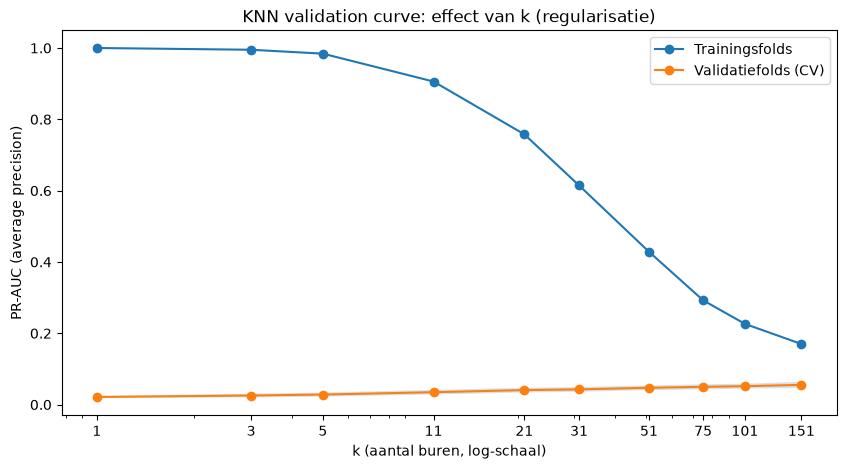

k,1,3,5,11,21,31,51,75,101,151
train PR-AUC,1.0000,0.9951,0.9842,0.9060,0.7579,0.6146,0.4286,0.2925,0.2264,0.1699
CV PR-AUC,0.0214,0.0255,0.0281,0.0348,0.0407,0.0427,0.0472,0.0498,0.0517,0.0554


In [23]:
# Lijst met k-waarden (aantal buren) die getest gaan worden 
k_waarden = [1, 3, 5, 11, 21, 31, 51, 75, 101, 151]

#de trainings- en validatiescores voor elke k-waarde berkenen met validation curve
train_scores, cv_scores = validation_curve(
    maak_pipeline(KNeighborsClassifier(), use_smote=True), #  # Pipeline met imputeren, SMOTE en een KNN (k wordt per keer overschreven
    X_tr, y_tr,   # Trainingsdata en labels
    # Parameter die gevarieerd wordt: n_neighbors in de classifier-stap
    param_name='classifier__n_neighbors', param_range=k_waarden,
    # 5-voudige gestratificeerde kruisvalidatie, PR-AUC als score, alle cores
    cv=cv_knn, scoring='average_precision', n_jobs=-1
)

# Visualisatie van de validation curve: PR-AUC (average precision) tegen k (aantal buren)
plt.figure(figsize=(10, 5))
# Plot de gemiddelde trainscore per k (met stippen en lijn)
plt.plot(k_waarden, train_scores.mean(axis=1), 'o-', label='Trainingsfolds')
# Plot de gemiddelde validatiescore per k (met stippen en lijn)
plt.plot(k_waarden, cv_scores.mean(axis=1), 'o-', label='Validatiefolds (CV)')

plt.fill_between(k_waarden, cv_scores.mean(axis=1) - cv_scores.std(axis=1),
                 cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.2)
# Zet de x-as op logaritmische schaal (k-waarden lopen sterk uiteen)
plt.xscale('log')
# de exacte k-waarden als as-labels
plt.xticks(k_waarden, k_waarden)
# Label op de x-as
plt.xlabel('k (aantal buren, log-schaal)')
# Label op de y-as
plt.ylabel('PR-AUC (average precision)')
# Titel van de grafiek
plt.title('KNN validation curve: effect van k (regularisatie)')
# Toon de legenda
plt.legend()
plt.grid(False)
plt.show()
#de gemiddelde train- en CV-scores in een tabel (4 decimalen)
display(pd.DataFrame({'k': k_waarden,
                      'train PR-AUC': train_scores.mean(axis=1),
                      'CV PR-AUC': cv_scores.mean(axis=1)}).round(4).set_index('k').T)

**Interpretatie validation curve:** bij $k = 1$ is de trainingsscore (bijna) perfect, terwijl de CV-score het laagst is: het model heeft de trainingsdata "uit het hoofd geleerd" (overfitting). Naarmate $k$ groeit, daalt de trainingsscore en stijgt de CV-score: het gat tussen beide wordt kleiner. Bij een zeldzame klasse als stroke heeft KNN relatief veel buren nodig voordat de kansschatting stabiel wordt (met $k = 5$ kan de kans alleen 0; 0,2; 0,4; ... zijn). Dit bevestigt dat we $k$ in de grid search ruim moeten kiezen.

### Hyperparameter tuning en imbalance-technieken voor KNN

We tunen met `GridSearchCV` (5-fold stratified CV, F1) via de gezamenlijke functie `train_en_evalueer`:

| Hyperparameter | Waarden | Betekenis |
|---|---|---|
| `n_neighbors` ($k$) | 5 – 101 | aantal buren / sterkte regularisatie |
| `weights` | uniform, distance | gelijke stem of stem gewogen met $1/d$ |
| `p` | 1, 2 | Manhattan of Euclidean afstand |
| `sampling_strategy` (alleen undersampling) | 0,1 – 1,0 | verhouding minderheid/meerderheid na undersampling |

Omdat KNN geen `class_weight` kent, roepen we `train_en_evalueer` direct aan voor drie varianten: **geen techniek**, **alleen SMOTE** en **alleen random undersampling**. Bij alle varianten wordt daarnaast de drempel getuned (threshold moving).

## Geen techniek en SMOTE

In [15]:
#import 
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone

# Grid met KNN-hyperparameters die geoptimaliseerd worden
knn_param_grid = {
    'classifier__n_neighbors': [5, 15, 31, 51, 75, 101], # 6 buren
    # Weights: 'uniform' (elke buur even zwaar) of 'distance' (dichterbij zwaarder)
    'classifier__weights': ['uniform', 'distance'],
    # Afstandsmetric: p=1 = Manhattan, p=2 = Euclidean
    'classifier__p': [1, 2],   # 1 = Manhattan, 2 = Euclidean
}

# Variant 1: geen imbalance-techniek (alleen drempel/ k tunen)
knn_geen = train_en_evalueer(KNeighborsClassifier(), knn_param_grid,
                             'KNN - Geen techniek', use_smote=False)
#resultaat opslaan in de dictionary 
knn_geen['imbalance_techniek'] = 'Geen techniek'

# Variant 2: KNN met SMOTE (oversampling van de minderheidsklasse)
knn_smote = train_en_evalueer(KNeighborsClassifier(), knn_param_grid,
                              'KNN - Alleen SMOTE', use_smote=True)
knn_smote['imbalance_techniek'] = 'Alleen SMOTE'

Fitting 5 folds for each of 24 candidates, totalling 120 fits

=== KNN - Geen techniek ===
Beste hyperparameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance'}
Beste CV F1-score: 0.0132
Gekozen classificatiedrempel: 0.10
Validatie F1-score: 0.0791
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6607
           1       0.05      0.19      0.08       103

    accuracy                           0.93      6710
   macro avg       0.52      0.57      0.52      6710
weighted avg       0.97      0.93      0.95      6710

Fitting 5 folds for each of 24 candidates, totalling 120 fits

=== KNN - Alleen SMOTE ===
Beste hyperparameters: {'classifier__n_neighbors': 31, 'classifier__p': 2, 'classifier__weights': 'distance'}
Beste CV F1-score: 0.0821
Gekozen classificatiedrempel: 0.72
Validatie F1-score: 0.0830
              precision    recall  f1-score   support

           0       0.99      0.91      0.9

## Random undersampling

In [19]:
# Variant 3: alleen random undersampling (KNN heeft geen class_weight).
# Het 'model' is een imblearn-pipeline met undersampler + KNN, zodat de
# undersampling binnen iedere CV-fold gebeurt en de gezamenlijke code
# (maak_pipeline / train_en_evalueer) ongewijzigd kan blijven.
knn_undersampling_model = ImbPipeline([
    #1: willekeurig overschrijven van de meerderheidsklasse tot de opgegeven verhouding
    ('undersampler', RandomUnderSampler(random_state=RANDOM_STATE)),
    #2: de KNN-classifier zelf (k, weights en p komen uit de grid)
    ('knn', KNeighborsClassifier())
])
# Grid met hyperparameters voor deze variant (4 × 4 × 2 × 2 = 64 combinaties)
knn_undersampling_grid = {
    # sampling_strategy: verhouding minderheid/meerderheid na undersampling (1.0 = gelijke aantallen)
    'classifier__undersampler__sampling_strategy': [0.1, 0.25, 0.5, 1.0],
    #aantal buren mogelijkheden
    'classifier__knn__n_neighbors': [5, 15, 31, 51],
    # Weights: 'uniform' (elke buur even zwaar) of 'distance' (dichterbij zwaarder)
    'classifier__knn__weights': ['uniform', 'distance'],
     # Afstandsmetric: p=1 = Manhattan, p=2 = Euclidean
    'classifier__knn__p': [1, 2],
}
# Train en evalueer deze variant met GridSearchCV 
knn_under = train_en_evalueer(knn_undersampling_model, knn_undersampling_grid,
                              'KNN - Alleen undersampling', use_smote=False)
# Sla op dat deze variant undersampling
knn_under['imbalance_techniek'] = 'Alleen undersampling'

Fitting 5 folds for each of 64 candidates, totalling 320 fits

=== KNN - Alleen undersampling ===
Beste hyperparameters: {'classifier__knn__n_neighbors': 51, 'classifier__knn__p': 1, 'classifier__knn__weights': 'uniform', 'classifier__undersampler__sampling_strategy': 0.5}
Beste CV F1-score: 0.1224
Gekozen classificatiedrempel: 0.55
Validatie F1-score: 0.1233
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6607
           1       0.08      0.26      0.12       103

    accuracy                           0.94      6710
   macro avg       0.53      0.61      0.55      6710
weighted avg       0.97      0.94      0.96      6710



In [20]:
def resultaten_tabel(resultaten: list) -> pd.DataFrame:
    """Zet een lijst met resultaten van train_en_evalueer om in een tabel."""
    return pd.DataFrame([{
        'model': r['naam'],
        'CV F1': r['cv_f1'],
        'validatie F1': r['val_f1'],
        'drempel': r['threshold'],
        'beste hyperparameters': r['beste_params'],
    } for r in resultaten]).set_index('model') #voor elk resultaat een rij en Zet 'model' als index van de tabel

#de resultaten van alle drie de KNN-varianten in één lijst
knn_alle_resultaten = [knn_geen, knn_smote, knn_under]
#de variant met de hoogste CV F1-score
knn_beste = max(knn_alle_resultaten, key=lambda r: r['cv_f1'])
#alle resultaten van de KNN-varianten opslaan in de dictionary van de beste variant
knn_beste['alle_techniek_resultaten'] = knn_alle_resultaten

print(f"Beste KNN-variant (hoogste CV F1): {knn_beste['naam']}")
# de resultaten van alle KNN-varianten in een overzichtelijke tabel, met volledige kolombreedte
with pd.option_context('display.max_colwidth', None):
    display(resultaten_tabel(knn_alle_resultaten).round(4))

Beste KNN-variant (hoogste CV F1): KNN - Alleen undersampling


,CV F1,validatie F1,drempel,beste hyperparameters
model,,,,
KNN - Geen techniek,0.0132,0.0791,0.10,"{'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance'}"
KNN - Alleen SMOTE,0.0821,0.0830,0.72,"{'classifier__n_neighbors': 31, 'classifier__p': 2, 'classifier__weights': 'distance'}"
KNN - Alleen undersampling,0.1224,0.1233,0.55,"{'classifier__knn__n_neighbors': 51, 'classifier__knn__p': 1, 'classifier__knn__weights': 'uniform', 'classifier__undersampler__sampling_strategy': 0.5}"


### Confusion matrix 


In [24]:
# Beste KNN-model: confusion matrix op de onafhankelijke validatieset
# Beste KNN-model: bereken de kansen op stroke voor de validatieset
knn_val_proba = knn_beste['beste_model'].predict_proba(X_val)[:, 1]
# Zet die kansen om in voorspellingen met de beste drempel (>= drempel = stroke)
knn_val_pred = (knn_val_proba >= knn_beste['threshold']).astype(int)
# Plot de confusion matrix op de onafhankelijke validatieset
ConfusionMatrixDisplay.from_predictions(
    y_val, knn_val_pred, display_labels=['geen stroke', 'stroke'],
    cmap='Blues', colorbar=False)
# Titel met de naam van het model, de validatie-F1 en de gebruikte drempel
plt.title(f"{knn_beste['naam']}\nvalidatie F1 = {knn_beste['val_f1']:.3f} "
          f"(drempel {knn_beste['threshold']:.2f})")
plt.show()
# Print de PR-AUC op de validatieset
print(f"PR-AUC validatie: {average_precision_score(y_val, knn_val_proba):.4f}")
# Print de ROC-AUC op de validatieset
print(f"ROC-AUC validatie: {roc_auc_score(y_val, knn_val_proba):.4f}")

NameError: name 'ConfusionMatrixDisplay' is not defined

### Voor- en nadelen van KNN

| **Voordelen**                                                                                                                        | **Nadelen**                                                                                                                                                                                                                                    |
| ------------------------------------------------------------------------------------------------------------------------------------ | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Eenvoudig en makkelijk te begrijpen:** het model kijkt naar patiënten die het meest op een nieuwe patiënt lijken.                  | **Voorspellingen kunnen traag zijn:** KNN moet de nieuwe patiënt vergelijken met alle patiënten in de trainingsdata.                                                                                                                           |
| **Maakt weinig aannames over de data:** KNN gaat niet uit van een bepaalde vorm of verdeling van de data.                            | **Gevoelig voor de schaal van kenmerken:** daarom is standaardisatie belangrijk.                                                                                                                                                               |
| **Kan complexe patronen herkennen:** KNN kan ook niet-lineaire verbanden tussen patiënten herkennen.                                 | **Minder geschikt bij veel kenmerken:** als er veel kenmerken zijn, wordt het moeilijker om goede "buren" te vinden. Dit heet de *curse of dimensionality*.                                                                                    |
| **Relatief weinig instellingen:** vooral \(k\), de afstandsmethode en de manier waarop buren worden gewogen moeten worden ingesteld. | **Niet makkelijk uit te leggen welke kenmerken belangrijk zijn:** KNN geeft geen duidelijke gewichten of coëfficiënten per kenmerk.                                                                                                            |
|                                                                                                                                      | **Gevoelig voor een ongelijke verdeling van de klassen:** bij een zeldzame klasse, zoals stroke, zijn veel van de dichtstbijzijnde buren waarschijnlijk patiënten zonder stroke. Hierdoor kan het model moeite hebben om strokes te herkennen. |


## Logistic regression 

### Hoe werkt het model?

Logistic Regression voorspelt de **kans dat een patiënt een stroke krijgt**. Het model gebruikt de kenmerken van een patiënt, zoals leeftijd, glucosewaarde en de aanwezigheid van hartziekten. Op basis hiervan berekent het een kans tussen 0 en 1.

Het model bestaat uit twee stappen.

**1. De kenmerken combineren**

Eerst combineert het model alle kenmerken met behulp van de volgende formule:

$$
z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_m x_m
$$

Je kunt dit lezen als: het model begint met een startwaarde en telt daar de bijdrage van ieder kenmerk bij op.

* $z$ is de uitkomst van de berekening.
* $\beta_0$ is de startwaarde, ook wel het intercept genoemd.
* $x_1, x_2, \dots, x_m$ zijn de kenmerken van de patiënt.
* $\beta_1, \beta_2, \dots, \beta_m$ zijn de coëfficiënten. Deze bepalen hoeveel invloed ieder kenmerk heeft op de uitkomst.
* $m$ is het totale aantal kenmerken.

Een kenmerk met een positieve coëfficiënt verhoogt de waarde van $z$. Een negatieve coëfficiënt verlaagt deze waarde. Dit zegt nog niet rechtstreeks hoeveel de kans op een stroke verandert.

**2. De uitkomst omzetten naar een kans**

De waarde van $z$ kan elk getal zijn. We willen echter een kans tussen 0 en 1. Daarom gebruikt Logistic Regression de sigmoid-functie:

$$
\hat{p} = P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1+e^{-z}}
$$

Je leest deze formule als: de sigmoid-functie zet de berekende waarde $z$ om in een kans.

* $\hat{p}$ is de voorspelde kans op een stroke.
* $P(y=1 \mid \mathbf{x})$ betekent de kans op een stroke, gegeven de kenmerken van de patiënt.
* $e$ is een vast wiskundig getal, ongeveer 2,718.
* $\sigma(z)$ is een andere schrijfwijze voor de sigmoid-functie.

De uitkomst ligt altijd tussen 0 en 1. Een kans van 0,80 betekent bijvoorbeeld dat het model een kans van 80% voorspelt.

**De logit-functie**

Logistic Regression kan ook worden beschreven met de logit-functie:

$$
\text{logit}(\hat{p}) =
\ln\left(\frac{\hat{p}}{1-\hat{p}}\right)
= \beta_0 + \boldsymbol{\beta}^T \mathbf{x}
$$

Deze formule ziet er ingewikkelder uit, maar het idee is eenvoudig: de logit zet een kans om naar de log-odds. De log-odds kunnen vervolgens lineair worden berekend met de kenmerken van de patiënt.

Hierbij geldt:

* $\hat{p}$ is de voorspelde kans op een stroke.
* $1-\hat{p}$ is de voorspelde kans op geen stroke.
* De odds zijn de verhouding tussen de kans op een stroke en de kans op geen stroke.
* $\ln$ is de natuurlijke logaritme.
* $\boldsymbol{\beta}^T\mathbf{x}$ staat voor de combinatie van alle kenmerken en hun coëfficiënten.

De logit-functie is vooral belangrijk omdat de invloed van de kenmerken hierdoor lineair wordt beschreven in de log-odds. Daarom hoort Logistic Regression bij de *generalized linear models*.